<a href="https://colab.research.google.com/github/ritzsaha/Transformer_Translator_Workshop/blob/main/Yet_another_copy_of_UTMIST_Transformer_Translator.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Build a Transformer Translator from Scratch

**UTMIST LLM Workshop Series · Workshops 1 & 2**

In this notebook you'll build the model from *Attention Is All You Need* (Vaswani et al., 2017) piece by piece in plain PyTorch, then train it to translate English into French on a free Colab GPU in about 10 minutes.

| | What you build | Workshop |
|---|---|---|
| **Part 1** | Data + tokenizer → embeddings + positions → attention → multi-head attention → encoder | Workshop 1 |
| **Part 2** | Causal mask → decoder → full encoder–decoder → training → translating | Workshop 2 |

**How this notebook works**

*  **Exercise** cells have a `# YOUR CODE HERE` spot. Most are 1–5 lines.
*  **Check** cells test your code. Green means move on.
*  **Solution** cells are collapsed. Stuck? Run the solution cell (no need to open it), then re-run the check. Peek inside afterwards.

**Before you start:** `Runtime → Change runtime type → T4 GPU`. Part 1 runs fine on CPU; you need the GPU for training in Part 2.

**Our model (small but real):** `d_model = 128`, 4 heads, 3 encoder + 3 decoder layers, feed-forward size 512, ~4,000-token BPE vocabularies. About 3 million parameters (GPT-2 small has 124 million).

In [1]:
# @title Setup: run me first
!pip -q install sacrebleu

import math, os, random, time, zipfile, urllib.request
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

torch.manual_seed(0)
random.seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch", torch.__version__, "| device:", device,
      f"({torch.cuda.get_device_name(0)})" if device == "cuda" else "(Part 1 is fine on CPU; switch to a GPU before training)")

def check(name, ok, hint=""):
    if ok:
        print(f"Passed: {name}")
    else:
        raise AssertionError(f"Error: {name}. {hint}")

PyTorch 2.14.1+cpu | device: cpu (Part 1 is fine on CPU; switch to a GPU before training)


---
# Part 1 · The encoder (Workshop 1)

## A. Data and tokenizer

We use English–French sentence pairs from **[Tatoeba](https://tatoeba.org)**, a crowd-sourced collection of short example sentences (about 135k pairs, mirrored by the PyTorch tutorials). Each line is `English<TAB>French`.

Short everyday sentences are perfect for a model this size: it can learn real French grammar in a few minutes.

In [2]:
DATA_URL = "https://download.pytorch.org/tutorial/data.zip"

if not os.path.exists("data/eng-fra.txt"):
    urllib.request.urlretrieve(DATA_URL, "data.zip")
    with zipfile.ZipFile("data.zip") as z:
        z.extract("data/eng-fra.txt")

pairs = []
with open("data/eng-fra.txt", encoding="utf-8") as f:
    for line in f:
        parts = line.rstrip("\n").split("\t")
        if len(parts) >= 2:
            pairs.append((parts[0], parts[1]))

random.shuffle(pairs)
print(f"{len(pairs):,} sentence pairs. A few examples:\n")
for en, fr in pairs[:6]:
    print(f"  EN: {en}\n  FR: {fr}\n")

135,842 sentence pairs. A few examples:

  EN: I knew this day would come.
  FR: Je savais que ce jour viendrait.

  EN: My wife isn't beautiful. Yours is.
  FR: Ma femme n'est pas belle. La tienne oui.

  EN: She wants to extend the no-smoking area.
  FR: Elle veut étendre la zone non-fumeurs.

  EN: I know I'm not the brightest girl in the world.
  FR: Je sais que je ne suis pas une lumière.

  EN: Let me write down the address.
  FR: Je vais noter l'adresse.

  EN: I'm at Tokyo Station now.
  FR: Je suis à la gare de Tokyo en ce moment.



### Tokenization with BPE

A network needs numbers, not strings. We split text into **tokens** and give each token an ID.

* Whole words → huge vocabulary, and any unseen word is unknown.
* Characters → tiny vocabulary, but very long sequences.
* **Byte-Pair Encoding (BPE)** sits in between: start from characters and repeatedly merge the most frequent adjacent pair. Common words become one token; rare words split into pieces (`▁trans` `formers`).

We train one BPE tokenizer per language with ~4,000 tokens each. The `▁` symbol marks "a space came before this piece". We also reserve four **special tokens**:

| ID | Token | Meaning |
|---|---|---|
| 0 | `<pad>` | filler so sentences in a batch have equal length |
| 1 | `<s>` | start of sentence (BOS) |
| 2 | `</s>` | end of sentence (EOS) |
| 3 | `<unk>` | anything the tokenizer can't represent |

In [3]:
from tokenizers import Tokenizer, models, trainers, pre_tokenizers, decoders, normalizers

SPECIALS = ["<pad>", "<s>", "</s>", "<unk>"]
PAD, BOS, EOS, UNK = 0, 1, 2, 3
VOCAB_SIZE = 4000

def train_bpe(texts, vocab_size=VOCAB_SIZE):
    tok = Tokenizer(models.BPE(unk_token="<unk>"))
    tok.normalizer = normalizers.Sequence([normalizers.NFKC(), normalizers.Lowercase()])
    tok.pre_tokenizer = pre_tokenizers.Metaspace()   # spaces become ▁
    tok.decoder = decoders.Metaspace()
    trainer = trainers.BpeTrainer(vocab_size=vocab_size, special_tokens=SPECIALS, min_frequency=2)
    tok.train_from_iterator(texts, trainer)
    return tok

en_tok = train_bpe(en for en, _ in pairs)
fr_tok = train_bpe(fr for _, fr in pairs)
print("EN vocab:", en_tok.get_vocab_size(), "| FR vocab:", fr_tok.get_vocab_size())

for s in ["Transformers are surprisingly simple.", "I don't understand tokenizers yet!"]:
    print(f"\n{s!r}\n  → {en_tok.encode(s).tokens}\n  → {en_tok.encode(s).ids}")

EN vocab: 4000 | FR vocab: 4000

'Transformers are surprisingly simple.'
  → ['▁trans', 'form', 'ers', '▁are', '▁surpris', 'ing', 'ly', '▁simp', 'le.']
  → [1789, 3850, 460, 159, 2035, 87, 224, 2325, 384]

"I don't understand tokenizers yet!"
  → ['▁i', "▁don't", '▁understand', '▁to', 'k', 'en', 'iz', 'ers', '▁yet', '!']
  → [66, 138, 702, 75, 38, 95, 565, 460, 2521, 4]


In [4]:
def encode(tok, text):
    # text → [BOS, ...token ids..., EOS]
    return [BOS] + tok.encode(text).ids + [EOS]

def decode(tok, ids):
    # token ids → text (drops BOS/PAD, stops at the first EOS)
    ids = [int(i) for i in ids]
    if EOS in ids:
        ids = ids[:ids.index(EOS)]
    return tok.decode([i for i in ids if i not in (PAD, BOS)])

# Round trip: decode(encode(s)) should give back s (lower-cased, unicode-normalized)
norm = lambda tok, s: " ".join(tok.normalizer.normalize_str(s).split())
sample = pairs[:300]
ok = sum(norm(en_tok, en) == " ".join(decode(en_tok, encode(en_tok, en)).split()) for en, _ in sample) / len(sample)
check(f"decode(encode(s)) gives the sentence back for {ok:.0%} of samples", ok > 0.95)

Passed: decode(encode(s)) gives the sentence back for 100% of samples


### Encode everything, split, and batch

We drop very long pairs (over `MAX_LEN` tokens) to keep training fast, and hold out 1,000 pairs for validation and 1,000 for testing.

Sentences in a batch have different lengths, so we **pad** the short ones with `<pad>` (ID 0) to form a rectangle.

In [5]:
MAX_LEN = 32
data = [(encode(en_tok, en), encode(fr_tok, fr), en, fr) for en, fr in pairs]
data = [d for d in data if len(d[0]) <= MAX_LEN and len(d[1]) <= MAX_LEN]
test_data, val_data, train_data = data[:1000], data[1000:2000], data[2000:]
print(f"train {len(train_data):,} | val {len(val_data):,} | test {len(test_data):,}")

def pad_batch(seqs):
    out = torch.full((len(seqs), max(map(len, seqs))), PAD, dtype=torch.long)
    for i, s in enumerate(seqs):
        out[i, :len(s)] = torch.tensor(s)
    return out

def batches(data, batch_size, shuffle=True):
    # Yields (src [B, S], tgt [B, T]) tensors on the GPU/CPU.
    idx = list(range(len(data)))
    if shuffle:
        random.shuffle(idx)
    for i in range(0, len(idx), batch_size):
        chunk = [data[j] for j in idx[i:i + batch_size]]
        yield pad_batch([c[0] for c in chunk]).to(device), pad_batch([c[1] for c in chunk]).to(device)

src, tgt = next(batches(train_data, 4))
print("src batch (English IDs), shape", tuple(src.shape))
print(src.cpu())

train 133,667 | val 1,000 | test 1,000
src batch (English IDs), shape (4, 11)
tensor([[   1,  142,  109, 3257,  179,    2,    0,    0,    0,    0,    0],
        [   1,   66,  403, 2448,   75,  137,  351,  326,  338,  552,    2],
        [   1,   66,  730,   74, 1742, 1650,    2,    0,    0,    0,    0],
        [   1,  233,  159,  239, 1899,   46,  119,  142,  912,    2,    0]])


### Exercise A1: the padding mask

Attention should never look at `<pad>` tokens: they're filler, not words. We describe "where not to look" with a boolean **mask**.

**Convention for this whole notebook: `True` means blocked (don't attend here).**

Return a mask of shape `[B, 1, S]`: `True` wherever the token is `PAD`. The middle dimension of size 1 lets the same mask broadcast across every query position later.

In [6]:
def make_pad_mask(tokens):
    '''tokens: [B, S] int tensor  →  [B, 1, S] bool tensor, True where tokens == PAD'''
    # ✏️ YOUR CODE HERE (1 line)
    return (tokens == PAD).unsqueeze(1)

In [7]:
toks = torch.tensor([[5, 6, 7, 0, 0],
                     [8, 9, 0, 0, 0]])
m = make_pad_mask(toks)
check("shape is [B, 1, S]", tuple(m.shape) == (2, 1, 5), f"got {tuple(m.shape)}")
check("True exactly at the pads", m.dtype == torch.bool and m.squeeze(1).tolist() ==
      [[False, False, False, True, True], [False, False, True, True, True]])

Passed: shape is [B, 1, S]
Passed: True exactly at the pads


In [ ]:
# @title Solution: run this cell if you're stuck, then re-run the check above
def make_pad_mask(tokens):
    '''tokens: [B, S] int tensor  →  [B, 1, S] bool tensor, True where tokens == PAD'''
    return (tokens == PAD).unsqueeze(1)

## B. Embeddings and positions

**Token embeddings.** An embedding is a learned lookup table: row *i* is the vector for token *i*. We multiply by $\sqrt{d_{model}}$, as in the paper, so the embeddings aren't drowned out by the position signal we add next.

**Why positions?** Attention compares every token with every other token, but nothing in that comparison says *where* a token is. Without help, "dog bites man" and "man bites dog" look identical. So we **add** a position vector to each token's embedding.

The paper uses fixed sine waves of different frequencies:

$$PE_{(pos,\,2i)} = \sin\!\left(\frac{pos}{10000^{2i/d_{model}}}\right) \qquad PE_{(pos,\,2i+1)} = \cos\!\left(\frac{pos}{10000^{2i/d_{model}}}\right)$$

Even dimensions get a sine, odd dimensions a cosine. Low dimensions wiggle fast, high dimensions slowly, like the hands of a clock.

In [8]:
class TokenEmbedding(nn.Module):
    def __init__(self, vocab_size, d_model):
        super().__init__()
        self.lookup = nn.Embedding(vocab_size, d_model, padding_idx=PAD)
        self.scale = math.sqrt(d_model)

    def forward(self, tokens):          # [B, S] → [B, S, d_model]
        return self.lookup(tokens) * self.scale

### Exercise B1: sinusoidal positions

Return a `[max_len, d_model]` tensor following the formula above. Hints: `torch.arange`, broadcasting a `[max_len, 1]` column against a `[d_model/2]` row, and slice assignment `pe[:, 0::2] = ...`.

In [9]:
def sinusoidal_positions(max_len, d_model):
    '''→ [max_len, d_model] float tensor of sine/cosine position encodings'''
    # YOUR CODE HERE (about 5 lines)
    #CLOCK ANALOGY => BY GEMINI
    # 1. Build an empty chart to record the clock hands for every word spot
    pe = torch.zeros(max_len, d_model)

    # 2. Number the word spots from 0 up to max_len - 1 (Word 0, Word 1, Word 2...)
    pos = torch.arange(0, max_len).float().unsqueeze(1)

    # 3. Calculate the spinning speeds for each clock hand (fast to super slow)
    div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))

    # 4. Multiply (Word Spot × Hand Speed) to find how far each hand has spun,
    #    then record its horizontal (sin) and vertical (cos) coordinates!
    pe[:, 0::2] = torch.sin(pos * div_term)
    pe[:, 1::2] = torch.cos(pos * div_term)

    return pe

Passed: shape is [max_len, d_model]
Passed: position 0 is [0, 1, 0, 1, ...]
Passed: even dims use sin
Passed: odd dims use cos


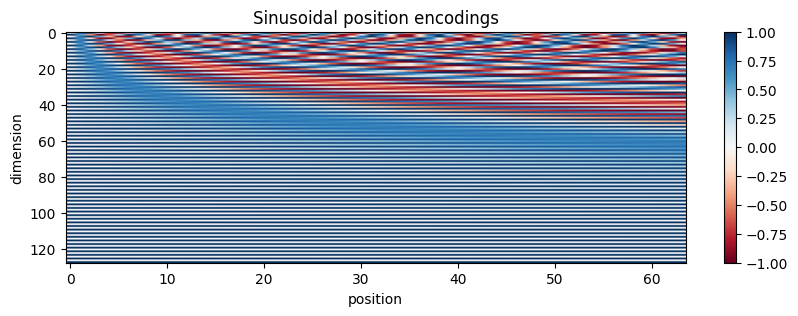

In [10]:
pe = sinusoidal_positions(50, 16)
check("shape is [max_len, d_model]", tuple(pe.shape) == (50, 16))
check("position 0 is [0, 1, 0, 1, ...]", torch.allclose(pe[0], torch.tensor([0., 1.] * 8)))
check("even dims use sin", abs(pe[3, 4].item() - math.sin(3 / 10000 ** (4 / 16))) < 1e-5)
check("odd dims use cos", abs(pe[3, 5].item() - math.cos(3 / 10000 ** (4 / 16))) < 1e-5)

plt.figure(figsize=(10, 3))
plt.imshow(sinusoidal_positions(64, 128).T, aspect="auto", cmap="RdBu")
plt.xlabel("position"); plt.ylabel("dimension"); plt.colorbar(); plt.title("Sinusoidal position encodings")
plt.show()

In [ ]:
# @title Solution: run this cell if you're stuck, then re-run the check above
def sinusoidal_positions(max_len, d_model):
    '''→ [max_len, d_model] float tensor of sine/cosine position encodings'''
    pos = torch.arange(max_len, dtype=torch.float).unsqueeze(1)          # [max_len, 1]
    two_i = torch.arange(0, d_model, 2, dtype=torch.float)               # [d_model/2]
    angle = pos / torch.pow(10000.0, two_i / d_model)                    # [max_len, d_model/2]
    pe = torch.zeros(max_len, d_model)
    pe[:, 0::2] = torch.sin(angle)
    pe[:, 1::2] = torch.cos(angle)
    return pe

In [11]:
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=512, dropout=0.1):
        super().__init__()
        self.register_buffer("pe", sinusoidal_positions(max_len, d_model))  # saved with the model, not trained
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):               # [B, S, d_model] → same shape
        return self.dropout(x + self.pe[: x.size(1)])

# Same word, two positions → two different vectors
emb, posenc = TokenEmbedding(en_tok.get_vocab_size(), 128), PositionalEncoding(128, dropout=0.0)
ids = torch.tensor([encode(en_tok, "the cat saw the dog")])
toks = en_tok.encode("the cat saw the dog").tokens
i, j = [k + 1 for k, t in enumerate(toks) if t == "▁the"][:2]      # +1 skips BOS
with torch.no_grad():
    before, after = emb(ids)[0], posenc(emb(ids))[0]
dist = lambda a, b: (a - b).norm().item()
print(f"'the' at positions {i} and {j}")
print(f"  distance between the two vectors, embedding only:      {dist(before[i], before[j]):.2f}")
print(f"  distance between the two vectors, embedding + position: {dist(after[i], after[j]):.2f}")
print("Same token, but the model can now tell the two apart. (The position signal is small next to the")
print("scaled embedding at first; training learns to make use of it.)")

'the' at positions 1 and 4
  distance between the two vectors, embedding only:      0.00
  distance between the two vectors, embedding + position: 4.86
Same token, but the model can now tell the two apart. (The position signal is small next to the
scaled embedding at first; training learns to make use of it.)


## C. Attention from scratch

Every token produces three vectors:

* a **query** $q$: "what am I looking for?"
* a **key** $k$: "what do I contain?"
* a **value** $v$: "what do I pass on if you pick me?"

Each query is compared with every key by a dot product. Softmax turns those scores into weights that sum to 1, and the output is the weighted average of the values:

$$\text{Attention}(Q, K, V) = \text{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}}\right)V$$

**Why $\sqrt{d_k}$?** Dot products of $d_k$-dimensional vectors grow like $\sqrt{d_k}$. Without the scaling, softmax saturates (one weight ≈ 1, the rest ≈ 0) and gradients vanish.

**Masking:** before the softmax, set blocked scores to $-\infty$. Then $e^{-\infty} = 0$, so blocked positions get exactly zero weight.

### Exercise C1: scaled dot-product attention

Write it so it works for any leading dimensions (`[..., L, d]`), so it handles batches and heads for free. Use `k.transpose(-2, -1)`, `masked_fill`, and `softmax(dim=-1)`.

In [12]:
def attention(q, k, v, mask=None):
    '''
    q: [..., Lq, d_k]   k: [..., Lk, d_k]   v: [..., Lk, d_v]
    mask: bool, broadcastable to [..., Lq, Lk]; True = blocked
    returns (output [..., Lq, d_v], weights [..., Lq, Lk])
    '''
    # YOUR CODE HERE (about 5 lines)
    d_k = q.size(-1)
    scores = torch.matmul(q, k.transpose(-2, -1)) / math.sqrt(d_k)
    if mask is not None:
      scores = scores.masked_fill(mask, float("-inf"))
    weights = F.softmax(scores, dim=-1)
    output = torch.matmul(weights, v)
    return output, weights

weights:
 [[0.108 0.446 0.446]
 [0.446 0.446 0.108]
 [0.248 0.503 0.248]] 
output Z:
 [[0.55 0.89]
 [0.55 0.55]
 [0.5  0.75]]
Passed: weights match the slide
Passed: output matches the slide
Passed: matches PyTorch to 4 decimals
Passed: masked keys get zero weight


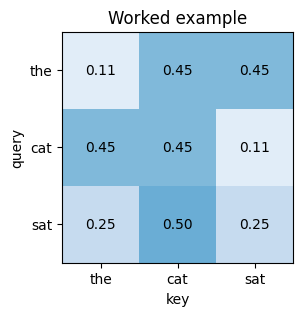

In [13]:
# The worked example from the slides: tokens "the", "cat", "sat"
Q = torch.tensor([[0., 2.], [2., 0.], [1., 1.]])
K = torch.tensor([[1., 0.], [1., 1.], [0., 1.]])
V = torch.tensor([[1., 0.], [0., 1.], [1., 1.]])
Z, W = attention(Q, K, V)
print("weights:\n", W.numpy().round(3), "\noutput Z:\n", Z.numpy().round(2))
check("weights match the slide", torch.allclose(W, torch.tensor(
    [[.108, .446, .446], [.446, .446, .108], [.248, .503, .248]]), atol=2e-3))
check("output matches the slide", torch.allclose(Z, torch.tensor(
    [[.55, .89], [.55, .55], [.50, .75]]), atol=6e-3))

# Against PyTorch's built-in version, with batches, heads and a padding mask
q, k, v = torch.randn(2, 4, 5, 8), torch.randn(2, 4, 7, 8), torch.randn(2, 4, 7, 8)
mask = torch.zeros(2, 1, 1, 7, dtype=torch.bool); mask[0, ..., 5:] = True   # last 2 keys of item 0 are padding
out, w = attention(q, k, v, mask)
ref = F.scaled_dot_product_attention(q, k, v, attn_mask=~mask)               # PyTorch uses True = allowed
check("matches PyTorch to 4 decimals", torch.allclose(out, ref, atol=1e-4))
check("masked keys get zero weight", w[0, ..., 5:].abs().max().item() == 0)

plt.figure(figsize=(3.2, 3))
plt.imshow(W, cmap="Blues", vmin=0, vmax=1)
plt.xticks(range(3), ["the", "cat", "sat"]); plt.yticks(range(3), ["the", "cat", "sat"])
plt.xlabel("key"); plt.ylabel("query"); plt.title("Worked example")
for a in range(3):
    for b in range(3):
        plt.text(b, a, f"{W[a, b]:.2f}", ha="center", va="center")
plt.show()

In [ ]:
# @title Solution: run this cell if you're stuck, then re-run the check above
def attention(q, k, v, mask=None):
    '''
    q: [..., Lq, d_k]   k: [..., Lk, d_k]   v: [..., Lk, d_v]
    mask: bool, broadcastable to [..., Lq, Lk]; True = blocked
    returns (output [..., Lq, d_v], weights [..., Lq, Lk])
    '''
    d_k = q.size(-1)
    scores = q @ k.transpose(-2, -1) / math.sqrt(d_k)           # [..., Lq, Lk]
    if mask is not None:
        scores = scores.masked_fill(mask, float("-inf"))        # blocked → -inf → weight 0
    weights = scores.softmax(dim=-1)                            # each row sums to 1
    return weights @ v, weights                                 # [..., Lq, d_v]

## D. Multi-head attention and the encoder block

### Multi-head attention

One attention pattern can only focus on one kind of relationship at a time. **Multi-head attention** runs `h` smaller attentions in parallel (here 4 heads × 32 dims = 128), each with its own learned $W_Q, W_K, W_V$, then concatenates them and mixes with $W_O$.

The trick is that we don't need `h` separate layers. We project once to `d_model`, then **reshape**:

```
[B, L, d_model] → view → [B, L, h, d_head] → transpose → [B, h, L, d_head]
```

Now the head dimension acts like an extra batch dimension, and your `attention` function handles all heads at once.

The same module does **self-attention** (queries, keys and values all from `x`) and, in Part 2, **cross-attention** (queries from the decoder, keys and values from the encoder).

### Exercise D1: `MultiHeadAttention.forward`

1. Project with `W_q` / `W_k` / `W_v` and split into heads.
2. The mask is `[B, Lq or 1, Lk]`. Add a head dimension with `mask.unsqueeze(1)` so it broadcasts over heads.
3. Call `attention`.
4. Store the weights in `self.last_weights` (use `.detach()`) so we can plot them later.
5. Merge heads and apply `W_o`, then dropout.

In [14]:
class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, n_heads, dropout=0.0):
        super().__init__()
        assert d_model % n_heads == 0
        self.h, self.d_head = n_heads, d_model // n_heads
        self.W_q = nn.Linear(d_model, d_model)
        self.W_k = nn.Linear(d_model, d_model)
        self.W_v = nn.Linear(d_model, d_model)
        self.W_o = nn.Linear(d_model, d_model)
        self.dropout = nn.Dropout(dropout)
        self.last_weights = None

    def split_heads(self, x):           # [B, L, d_model] → [B, h, L, d_head]
        B, L, _ = x.shape
        return x.view(B, L, self.h, self.d_head).transpose(1, 2)

    def merge_heads(self, x):           # [B, h, L, d_head] → [B, L, d_model]
        B, h, L, d_head = x.shape
        return x.transpose(1, 2).reshape(B, L, h * d_head)

    def forward(self, x_q, x_kv=None, mask=None):
        '''
        x_q:  [B, Lq, d_model]  (queries come from here)
        x_kv: [B, Lk, d_model]  (keys/values come from here; None means self-attention)
        mask: [B or 1, Lq or 1, Lk] bool, True = blocked
        returns [B, Lq, d_model]
        '''
        if x_kv is None:
            x_kv = x_q
        # 1. Project inputs to Q, K, V
        q = self.W_q(x_q)
        k = self.W_k(x_kv)
        v = self.W_v(x_kv)

        # 2. Split into subspaces
        q = self.split_heads(q)
        k = self.split_heads(k)
        v = self.split_heads(v)

        if mask is not None:
            mask = mask.unsqueeze(1)

        # 3. Run scaled dot-product attention across all heads in parallel
        out, self.last_weights = attention(q, k, v, mask)

        # 4. merege heads back
        out = self.merge_heads(out)

        return self.dropout(self.W_o(out))

In [15]:
torch.manual_seed(0)
mha = MultiHeadAttention(16, 4).eval()
ref = nn.MultiheadAttention(16, 4, batch_first=True).eval()
with torch.no_grad():   # give PyTorch's layer exactly our weights
    ref.in_proj_weight.copy_(torch.cat([mha.W_q.weight, mha.W_k.weight, mha.W_v.weight]))
    ref.in_proj_bias.copy_(torch.cat([mha.W_q.bias, mha.W_k.bias, mha.W_v.bias]))
    ref.out_proj.weight.copy_(mha.W_o.weight); ref.out_proj.bias.copy_(mha.W_o.bias)

x = torch.randn(2, 5, 16)
pm = make_pad_mask(torch.tensor([[4, 4, 4, 4, 4], [4, 4, 4, 0, 0]]))
ours = mha(x, mask=pm)
theirs, _ = ref(x, x, x, key_padding_mask=pm.squeeze(1))
check("self-attention output shape", tuple(ours.shape) == (2, 5, 16))
check("self-attention matches nn.MultiheadAttention", torch.allclose(ours, theirs, atol=1e-5))
check("stored weights have shape [B, h, Lq, Lk]", mha.last_weights is not None and tuple(mha.last_weights.shape) == (2, 4, 5, 5))

y = torch.randn(2, 3, 16)   # cross-attention: 3 queries attend over 5 keys
ours = mha(y, x, mask=pm)
theirs, _ = ref(y, x, x, key_padding_mask=pm.squeeze(1))
check("cross-attention matches nn.MultiheadAttention", torch.allclose(ours, theirs, atol=1e-5))

Passed: self-attention output shape
Passed: self-attention matches nn.MultiheadAttention
Passed: stored weights have shape [B, h, Lq, Lk]
Passed: cross-attention matches nn.MultiheadAttention


In [ ]:
# @title Solution: run this cell if you're stuck, then re-run the check above
class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, n_heads, dropout=0.0):
        super().__init__()
        assert d_model % n_heads == 0
        self.h, self.d_head = n_heads, d_model // n_heads
        self.W_q = nn.Linear(d_model, d_model)
        self.W_k = nn.Linear(d_model, d_model)
        self.W_v = nn.Linear(d_model, d_model)
        self.W_o = nn.Linear(d_model, d_model)
        self.dropout = nn.Dropout(dropout)
        self.last_weights = None

    def split_heads(self, x):           # [B, L, d_model] → [B, h, L, d_head]
        B, L, _ = x.shape
        return x.view(B, L, self.h, self.d_head).transpose(1, 2)

    def merge_heads(self, x):           # [B, h, L, d_head] → [B, L, d_model]
        B, h, L, d_head = x.shape
        return x.transpose(1, 2).reshape(B, L, h * d_head)

    def forward(self, x_q, x_kv=None, mask=None):
        if x_kv is None:
            x_kv = x_q
        q = self.split_heads(self.W_q(x_q))          # [B, h, Lq, d_head]
        k = self.split_heads(self.W_k(x_kv))         # [B, h, Lk, d_head]
        v = self.split_heads(self.W_v(x_kv))         # [B, h, Lk, d_head]
        if mask is not None:
            mask = mask.unsqueeze(1)                 # [B, 1, Lq|1, Lk]: broadcasts over heads
        out, w = attention(q, k, v, mask)            # [B, h, Lq, d_head]
        self.last_weights = w.detach()
        return self.dropout(self.W_o(self.merge_heads(out)))   # [B, Lq, d_model]

### LayerNorm

LayerNorm rescales each token's vector to mean 0 and variance 1 across its features, then applies a learned scale $\gamma$ and shift $\beta$:

$$\text{LN}(x) = \gamma \odot \frac{x - \mu}{\sqrt{\sigma^2 + \epsilon}} + \beta$$

where $\mu$ and $\sigma^2$ are the mean and variance over the **last** dimension, computed separately for every token. This keeps activations in a sensible range as they flow through many layers.

### ✏️ Exercise D2: LayerNorm
Use `x.mean(-1, keepdim=True)` and `x.var(-1, keepdim=True, unbiased=False)`.

In [16]:
class LayerNorm(nn.Module):
    def __init__(self, d_model, eps=1e-5):
        super().__init__()
        self.gamma = nn.Parameter(torch.ones(d_model))
        self.beta = nn.Parameter(torch.zeros(d_model))
        self.eps = eps

    def forward(self, x):               # [..., d_model] → same shape
        # ✏️ YOUR CODE HERE (about 3 lines)
        mean = x.mean(dim=-1, keepdim=True)
        var = x.var(dim=-1, keepdim=True, unbiased=False)
        return self.gamma * (x - mean) / torch.sqrt(var + self.eps) + self.beta

In [17]:
x = torch.randn(2, 5, 16) * 3 + 1
ln, ref = LayerNorm(16), nn.LayerNorm(16)
with torch.no_grad():
    ln.gamma.uniform_(0.5, 1.5); ln.beta.uniform_(-1, 1)
    ref.weight.copy_(ln.gamma); ref.bias.copy_(ln.beta)
check("matches nn.LayerNorm", torch.allclose(ln(x), ref(x), atol=1e-5))

Passed: matches nn.LayerNorm


In [ ]:
# @title Solution: run this cell if you're stuck, then re-run the check above
class LayerNorm(nn.Module):
    def __init__(self, d_model, eps=1e-5):
        super().__init__()
        self.gamma = nn.Parameter(torch.ones(d_model))
        self.beta = nn.Parameter(torch.zeros(d_model))
        self.eps = eps

    def forward(self, x):
        mu = x.mean(-1, keepdim=True)
        var = x.var(-1, keepdim=True, unbiased=False)
        return self.gamma * (x - mu) / torch.sqrt(var + self.eps) + self.beta

### The feed-forward layer

After attention has moved information *between* tokens, each token goes through the same small MLP *on its own*: expand 4× (128 → 512), ReLU, project back. This one is given.

In [18]:
class FeedForward(nn.Module):
    def __init__(self, d_model, d_ff, dropout=0.1):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d_model, d_ff), nn.ReLU(), nn.Dropout(dropout), nn.Linear(d_ff, d_model))

    def forward(self, x):               # [B, L, d_model] → same shape
        return self.net(x)

### Exercise D3: the encoder layer

An encoder layer has two **sublayers**, each wrapped in a **residual connection**: the sublayer's output is *added* to its input, so information (and gradients) can flow straight through the stack. That running sum is the **residual stream**.

The 2017 paper normalizes *after* adding (**post-LN**): `x = LN(x + sublayer(x))`.
We use the GPT-2 style **pre-LN**, which trains more stably without careful tuning:

```
x = x + dropout(self_attn(LN₁(x), mask))
x = x + dropout(ff(LN₂(x)))
```

In [19]:
class EncoderLayer(nn.Module):
    def __init__(self, d_model, n_heads, d_ff, dropout=0.1):
        super().__init__()
        self.ln1 = LayerNorm(d_model)
        self.self_attn = MultiHeadAttention(d_model, n_heads, dropout)
        self.ln2 = LayerNorm(d_model)
        self.ff = FeedForward(d_model, d_ff, dropout)
        self.drop = nn.Dropout(dropout)

    def forward(self, x, mask):         # x: [B, S, d_model], mask: [B, 1, S]
        # YOUR CODE HERE (2 lines + return)
        # 1. Attention sub-layer with residual connection
        x = x + self.drop(self.self_attn(self.ln1(x), x_kv=None, mask=mask))
        # 2. Feed-Forward sub-layer with residual connection
        x = x + self.drop(self.ff(self.ln2(x)))
        return x

In [20]:
layer = EncoderLayer(16, 4, 64).eval()
x = torch.randn(2, 5, 16)
pm = make_pad_mask(torch.tensor([[4, 4, 4, 4, 4], [4, 4, 4, 0, 0]]))
out = layer(x, pm)
check("shape unchanged", out.shape == x.shape)
with torch.no_grad():
    expect = x + layer.self_attn(layer.ln1(x), mask=pm)
    expect = expect + layer.ff(layer.ln2(expect))
check("pre-LN residual structure", torch.allclose(out, expect, atol=1e-5),
      "x = x + attn(ln1(x)); x = x + ff(ln2(x))")

Passed: shape unchanged
Passed: pre-LN residual structure


In [ ]:
# @title Solution: run this cell if you're stuck, then re-run the check above
class EncoderLayer(nn.Module):
    def __init__(self, d_model, n_heads, d_ff, dropout=0.1):
        super().__init__()
        self.ln1 = LayerNorm(d_model)
        self.self_attn = MultiHeadAttention(d_model, n_heads, dropout)
        self.ln2 = LayerNorm(d_model)
        self.ff = FeedForward(d_model, d_ff, dropout)
        self.drop = nn.Dropout(dropout)

    def forward(self, x, mask):
        x = x + self.drop(self.self_attn(self.ln1(x), mask=mask))   # tokens talk to each other
        x = x + self.drop(self.ff(self.ln2(x)))                     # each token thinks on its own
        return x

### Stack them: the encoder

The encoder is `N` identical layers plus a final LayerNorm (needed with pre-LN, since the last residual add is never normalized otherwise). Let's run three layers on a real batch.

In [21]:
class Encoder(nn.Module):
    def __init__(self, n_layers, d_model, n_heads, d_ff, dropout=0.1):
        super().__init__()
        self.layers = nn.ModuleList([EncoderLayer(d_model, n_heads, d_ff, dropout) for _ in range(n_layers)])
        self.ln = LayerNorm(d_model)

    def forward(self, x, mask):         # [B, S, d_model] → same shape
        for layer in self.layers:
            x = layer(x, mask)
        return self.ln(x)

D_MODEL, N_HEADS, N_LAYERS, D_FF, DROPOUT = 128, 4, 3, 512, 0.1

torch.manual_seed(0)
embed = TokenEmbedding(en_tok.get_vocab_size(), D_MODEL)
posenc = PositionalEncoding(D_MODEL, dropout=0.0)
encoder = Encoder(N_LAYERS, D_MODEL, N_HEADS, D_FF).eval()

src, _ = next(batches(val_data, 8, shuffle=False))
src = src.cpu()
with torch.no_grad():
    memory = encoder(posenc(embed(src)), make_pad_mask(src))
print("input tokens:", tuple(src.shape), "→ encoder output:", tuple(memory.shape))
check("one d_model vector per input token", memory.shape == (*src.shape, D_MODEL))

w = encoder.layers[0].self_attn.last_weights            # [B, h, S, S]
pad_cols = (src == PAD).unsqueeze(1).unsqueeze(2).expand_as(w)
check("padding receives zero attention", w[pad_cols].abs().max().item() == 0 if pad_cols.any() else True)

# Padding must not change the result for the real tokens
one = src[:1, : (src[0] != PAD).sum()]                  # first sentence without its padding
with torch.no_grad():
    alone = encoder(posenc(embed(one)), make_pad_mask(one))
check("same sentence alone vs. in a padded batch → same vectors", torch.allclose(alone[0], memory[0, : one.size(1)], atol=1e-4))

input tokens: (8, 11) → encoder output: (8, 11, 128)
Passed: one d_model vector per input token
Passed: padding receives zero attention
Passed: same sentence alone vs. in a padded batch → same vectors


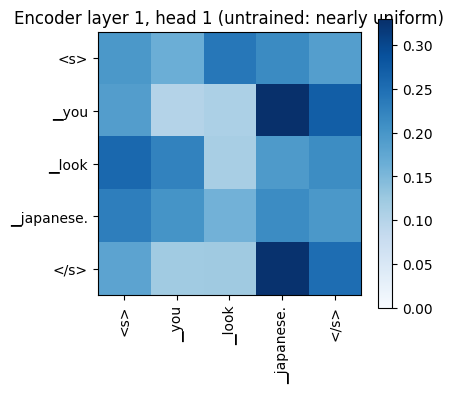

In [22]:
def show_attention(weights, x_labels, y_labels, title=""):
    plt.figure(figsize=(0.45 * len(x_labels) + 2, 0.45 * len(y_labels) + 1.5))
    plt.imshow(weights, cmap="Blues", vmin=0)
    plt.xticks(range(len(x_labels)), x_labels, rotation=90)
    plt.yticks(range(len(y_labels)), y_labels)
    plt.title(title); plt.colorbar(); plt.show()

labels = [en_tok.id_to_token(int(t)) for t in src[0] if t != PAD]
n = len(labels)
show_attention(encoder.layers[0].self_attn.last_weights[0, 0, :n, :n], labels, labels,
               "Encoder layer 1, head 1 (untrained: nearly uniform)")

### End of Part 1

You've built every piece of the encoder: tokenizer → embeddings + positions → multi-head self-attention → feed-forward → residual stream with LayerNorm → a stack of layers.

Right now the weights are random, so the attention map above is mush. Next workshop we add the **decoder**, connect the two with **cross-attention**, and train the whole thing. Then these maps start lining up English words with their French translations.

*Running ahead? Read the Part 2 intro, or try: what happens to the "same word, two positions" similarity if you remove the positional encoding?*

---
# Part 2 · The decoder, training and translating (Workshop 2)

> Fresh Colab session? Switch to a GPU, then `Runtime → Run all` (solutions included) to rebuild Part 1. It stops at the first exercise you haven't solved; run that cell and continue.

The **decoder** writes the French sentence one token at a time. Each decoder layer has **three** sublayers:

1. **Masked self-attention** over the French generated so far. It must not peek at future tokens.
2. **Cross-attention**: queries from the decoder, keys and values from the encoder output. This is where French looks at English.
3. **Feed-forward**, as before.

## E. The causal mask and the decoder

During training we feed the whole correct French sentence at once (fast and parallel), so we must stop position *t* from looking at positions after *t*. Otherwise it could just copy the next word.

### Exercise E1: causal mask
Return a `[1, L, L]` bool tensor that is `True` **above** the diagonal (the future). Hint: `torch.triu(..., diagonal=1)`.

In [23]:
def make_causal_mask(L, device=None):
    '''→ [1, L, L] bool, True where key position > query position (the future is blocked)'''
    # YOUR CODE HERE (1 line)
    return torch.triu(torch.ones(L, L, dtype=torch.bool, device=device), diagonal=1).unsqueeze(0)

tensor([[[0, 1, 1, 1],
         [0, 0, 1, 1],
         [0, 0, 0, 1],
         [0, 0, 0, 0]]], dtype=torch.int32)
Passed: shape [1, L, L]
Passed: True strictly above the diagonal


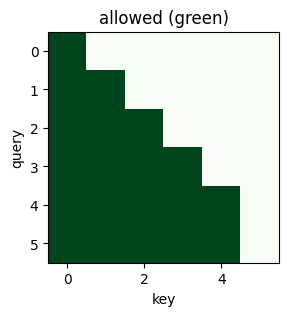

In [24]:
cm = make_causal_mask(4)
print(cm.int())
check("shape [1, L, L]", tuple(cm.shape) == (1, 4, 4))
check("True strictly above the diagonal", cm.dtype == torch.bool and cm[0].tolist() == [
    [False, True, True, True], [False, False, True, True], [False, False, False, True], [False, False, False, False]])

# Decoder self-attention combines both masks: no padding AND no future
tgt_example = torch.tensor([[BOS, 7, 8, 9, EOS, PAD]])
combined = make_pad_mask(tgt_example) | make_causal_mask(6)        # [1, 1, 6] | [1, 6, 6] → [1, 6, 6]
plt.figure(figsize=(3, 3)); plt.imshow(~combined[0], cmap="Greens")
plt.title("allowed (green)"); plt.xlabel("key"); plt.ylabel("query"); plt.show()

In [ ]:
# @title Solution: run this cell if you're stuck, then re-run the check above
def make_causal_mask(L, device=None):
    '''→ [1, L, L] bool, True where key position > query position (the future is blocked)'''
    return torch.triu(torch.ones(L, L, dtype=torch.bool, device=device), diagonal=1).unsqueeze(0)

### Exercise E2: the decoder layer

Same pre-LN pattern as the encoder, with three sublayers:

```
x = x + dropout(self_attn(LN₁(x), mask=tgt_mask))               # look back at earlier French
x = x + dropout(cross_attn(LN₂(x), memory, mask=src_mask))     # look at the English
x = x + dropout(ff(LN₃(x)))
```

`memory` is the encoder output; it's already normalized, so don't LayerNorm it again.

In [25]:
class DecoderLayer(nn.Module):
    def __init__(self, d_model, n_heads, d_ff, dropout=0.1):
        super().__init__()
        self.ln1, self.ln2, self.ln3 = LayerNorm(d_model), LayerNorm(d_model), LayerNorm(d_model)
        self.self_attn = MultiHeadAttention(d_model, n_heads, dropout)
        self.cross_attn = MultiHeadAttention(d_model, n_heads, dropout)
        self.ff = FeedForward(d_model, d_ff, dropout)
        self.drop = nn.Dropout(dropout)

    def forward(self, x, memory, tgt_mask, src_mask):
        '''x: [B, T, d_model]  memory: [B, S, d_model]  tgt_mask: [B, T, T]  src_mask: [B, 1, S]'''
        # ✏️ YOUR CODE HERE (3 lines + return)
        x = x + self.drop(self.self_attn(self.ln1(x), mask = tgt_mask))
        x = x + self.drop(self.cross_attn(self.ln2(x), memory, mask = src_mask))
        x = x + self.drop(self.ff(self.ln3(x)))
        return x

In [26]:
torch.manual_seed(0)
layer = DecoderLayer(16, 4, 64).eval()
x, mem = torch.randn(2, 4, 16), torch.randn(2, 6, 16)
tm = make_causal_mask(4).expand(2, 4, 4)
sm = make_pad_mask(torch.tensor([[5] * 6, [5, 5, 5, 5, 0, 0]]))
out = layer(x, mem, tm, sm)
check("shape follows the target", out.shape == x.shape)
with torch.no_grad():
    e = x + layer.self_attn(layer.ln1(x), mask=tm)
    e = e + layer.cross_attn(layer.ln2(e), mem, mask=sm)
    e = e + layer.ff(layer.ln3(e))
check("self-attn → cross-attn → FFN, pre-LN", torch.allclose(out, e, atol=1e-5))
check("cross-attention weights are [B, h, T, S]", tuple(layer.cross_attn.last_weights.shape) == (2, 4, 4, 6))

Passed: shape follows the target
Passed: self-attn → cross-attn → FFN, pre-LN
Passed: cross-attention weights are [B, h, T, S]


In [ ]:
# @title Solution: run this cell if you're stuck, then re-run the check above
class DecoderLayer(nn.Module):
    def __init__(self, d_model, n_heads, d_ff, dropout=0.1):
        super().__init__()
        self.ln1, self.ln2, self.ln3 = LayerNorm(d_model), LayerNorm(d_model), LayerNorm(d_model)
        self.self_attn = MultiHeadAttention(d_model, n_heads, dropout)
        self.cross_attn = MultiHeadAttention(d_model, n_heads, dropout)
        self.ff = FeedForward(d_model, d_ff, dropout)
        self.drop = nn.Dropout(dropout)

    def forward(self, x, memory, tgt_mask, src_mask):
        x = x + self.drop(self.self_attn(self.ln1(x), mask=tgt_mask))
        x = x + self.drop(self.cross_attn(self.ln2(x), memory, mask=src_mask))
        x = x + self.drop(self.ff(self.ln3(x)))
        return x

In [27]:
class Decoder(nn.Module):
    def __init__(self, n_layers, d_model, n_heads, d_ff, dropout=0.1):
        super().__init__()
        self.layers = nn.ModuleList([DecoderLayer(d_model, n_heads, d_ff, dropout) for _ in range(n_layers)])
        self.ln = LayerNorm(d_model)

    def forward(self, x, memory, tgt_mask, src_mask):
        for layer in self.layers:
            x = layer(x, memory, tgt_mask, src_mask)
        return self.ln(x)

## F. Assemble the translator

```
English IDs ─► embed + positions ─► Encoder ─► memory ─┐
                                                       ▼ (cross-attention)
French IDs so far ─► embed + positions ─► Decoder ─► Linear ─► logits over the French vocabulary
```

The final `Linear` (the "generator" or unembedding) turns each decoder vector into one score per French token: a guess for the **next** token.

### Exercise F1: `encode` and `decode`
* `encode(src)`: build the padding mask, embed + add positions, run the encoder. Return `(memory, src_mask)`.
* `decode(tgt, memory, src_mask)`: the target mask is padding **or** future, `make_pad_mask(tgt) | make_causal_mask(T, tgt.device)`. Embed + positions, run the decoder, apply the generator. Return logits `[B, T, V_fr]`.

In [ ]:
class Translator(nn.Module):
    def __init__(self, src_vocab, tgt_vocab, d_model=D_MODEL, n_heads=N_HEADS, n_layers=N_LAYERS,
                 d_ff=D_FF, dropout=DROPOUT):
        super().__init__()
        self.src_embed = TokenEmbedding(src_vocab, d_model)
        self.tgt_embed = TokenEmbedding(tgt_vocab, d_model)
        self.pos = PositionalEncoding(d_model, dropout=dropout)
        self.encoder = Encoder(n_layers, d_model, n_heads, d_ff, dropout)
        self.decoder = Decoder(n_layers, d_model, n_heads, d_ff, dropout)
        self.generator = nn.Linear(d_model, tgt_vocab)
        for p in self.parameters():               # Xavier init, as in the reference implementations
            if p.dim() > 1:
                nn.init.xavier_uniform_(p)

    def encode(self, src):
        '''src: [B, S] → (memory [B, S, d_model], src_mask [B, 1, S])'''
        # 1. Create the source padding mask so the encoder ignores [PAD] token
        src_mask = make_pad_mask(src)
        # 2. Turn English token IDs into vectors and add positional encodings
        x = self.pos(self.src_embed(src))
        # 3. Pass through the stacked encoder layers to produce the context memory
        memory = self.encoder(x, src_mask)
        return memory, src_mask

    def decode(self, tgt, memory, src_mask):
        '''tgt: [B, T] → logits [B, T, tgt_vocab]'''
        # ✏️ YOUR CODE HERE (about 3 lines)
        # 1. Get the current sequence length (T) of the target French tokens
        T = tgt.size(1)
        # 2. Combine the padding mask and the causal mask using a bitwise OR (|)
        tgt_mask = make_pad_mask(tgt) | make_casual_mask(T, tgt.device)
        # 3. Turn French token IDs into vectors and add positional encodings
        x = self.pos(self.tgt_embed(tgt))
        # 4. Pass through the decoder stack (handles masked self-attn + cross-attn)
        x = self.decoder(x, memory, tgt_mask, src_mask)
        # 5. Project the final decoder vectors into logits over the entire French vocabulary
        logits = self.generator(x)
        return logits
        # THERE IS SOMETHING WRONG HERE

    def forward(self, src, tgt):
        memory, src_mask = self.encode(src)
        return self.decode(tgt, memory, src_mask)

In [29]:
V_EN, V_FR = en_tok.get_vocab_size(), fr_tok.get_vocab_size()
torch.manual_seed(0)
model = Translator(V_EN, V_FR).to(device)
print(f"{sum(p.numel() for p in model.parameters()):,} parameters")

src, tgt = next(batches(train_data, 16))
model.eval()
with torch.no_grad():
    logits = model(src, tgt)
check("logits shape [B, T, V_fr]", tuple(logits.shape) == (*tgt.shape, V_FR))

# Causality: changing future French tokens must not change earlier predictions
tgt2 = tgt.clone(); tgt2[:, 3:] = 5
with torch.no_grad():
    logits2 = model(src, tgt2)
check("no peeking at the future", torch.allclose(logits[:, :3], logits2[:, :3], atol=1e-4),
      "did you include the causal mask in decode?")

2,929,056 parameters
Passed: logits shape [B, T, V_fr]
Passed: no peeking at the future


In [28]:
# @title Solution: run this cell if you're stuck, then re-run the check above
class Translator(nn.Module):
    def __init__(self, src_vocab, tgt_vocab, d_model=D_MODEL, n_heads=N_HEADS, n_layers=N_LAYERS,
                 d_ff=D_FF, dropout=DROPOUT):
        super().__init__()
        self.src_embed = TokenEmbedding(src_vocab, d_model)
        self.tgt_embed = TokenEmbedding(tgt_vocab, d_model)
        self.pos = PositionalEncoding(d_model, dropout=dropout)
        self.encoder = Encoder(n_layers, d_model, n_heads, d_ff, dropout)
        self.decoder = Decoder(n_layers, d_model, n_heads, d_ff, dropout)
        self.generator = nn.Linear(d_model, tgt_vocab)
        for p in self.parameters():
            if p.dim() > 1:
                nn.init.xavier_uniform_(p)

    def encode(self, src):
        src_mask = make_pad_mask(src)                                        # [B, 1, S]
        memory = self.encoder(self.pos(self.src_embed(src)), src_mask)       # [B, S, d_model]
        return memory, src_mask

    def decode(self, tgt, memory, src_mask):
        tgt_mask = make_pad_mask(tgt) | make_causal_mask(tgt.size(1), tgt.device)   # [B, T, T]
        x = self.decoder(self.pos(self.tgt_embed(tgt)), memory, tgt_mask, src_mask)  # [B, T, d_model]
        return self.generator(x)                                             # [B, T, V_fr]

    def forward(self, src, tgt):
        memory, src_mask = self.encode(src)
        return self.decode(tgt, memory, src_mask)

## G. The loss, and two sanity checks

**Teacher forcing.** We give the decoder the correct French shifted right by one, and ask it to predict each next token:

```
decoder input  (tgt_in):   <s>   le    chat  dort
should predict (tgt_out):  le    chat  dort  </s>
```

So `tgt_in = tgt[:, :-1]` and `tgt_out = tgt[:, 1:]`. The loss is cross-entropy between the logits and `tgt_out`, ignoring `PAD` positions.

### Exercise G1: `compute_loss`
`nn.CrossEntropyLoss` wants logits as `[N, V]` and targets as `[N]`, so flatten with `.reshape(-1, V)` and `.reshape(-1)`.

In [30]:
def compute_loss(model, src, tgt, criterion):
    # YOUR CODE HERE (about 4 lines)
    tgt_in, tgt_out = tgt[:, :-1], tgt[:, 1:]
    logits = model(src, tgt_in)
    return criterion(logits.reshape(-1, logits.size(-1)), tgt_out.reshape(-1))

In [31]:
plain_ce = nn.CrossEntropyLoss(ignore_index=PAD)
torch.manual_seed(0)
model = Translator(V_EN, V_FR).to(device)
src, tgt = next(batches(train_data, 64))
with torch.no_grad():
    loss0 = compute_loss(model.eval(), src, tgt, plain_ce).item()
print(f"loss at init: {loss0:.2f}   vs   ln(V_fr) = {math.log(V_FR):.2f}")
check("an untrained model is about as unsure as uniform guessing", abs(loss0 - math.log(V_FR)) < 1.0)

# Sanity check 2: a working model can memorize one small batch
src, tgt = next(batches(train_data, 32))
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
model.train()
for step in range(1, 201):
    loss = compute_loss(model, src, tgt, plain_ce)
    opt.zero_grad(); loss.backward(); opt.step()
    if step % 50 == 0:
        print(f"step {step:3d}  loss {loss.item():.3f}")
check("overfits one batch (loss < 0.5)", loss.item() < 0.5, "check the shift: tgt_in = tgt[:, :-1], tgt_out = tgt[:, 1:]")

loss at init: 8.32   vs   ln(V_fr) = 8.29
Passed: an untrained model is about as unsure as uniform guessing
step  50  loss 2.991
step 100  loss 0.347
step 150  loss 0.070
step 200  loss 0.034
Passed: overfits one batch (loss < 0.5)


In [ ]:
# @title Solution: run this cell if you're stuck, then re-run the check above
def compute_loss(model, src, tgt, criterion):
    tgt_in, tgt_out = tgt[:, :-1], tgt[:, 1:]          # teacher forcing: predict the next token
    logits = model(src, tgt_in)                         # [B, T-1, V]
    return criterion(logits.reshape(-1, logits.size(-1)), tgt_out.reshape(-1))

## H. Train it

Two tricks from the paper:

* **Learning-rate warm-up.** Adam's early updates are noisy, so we ramp the learning rate up linearly for `WARMUP` steps, then decay it like $1/\sqrt{\text{step}}$:
  $$\text{lr} = \text{factor}\cdot d_{model}^{-0.5}\cdot\min\!\left(\text{step}^{-0.5},\ \text{step}\cdot\text{warmup}^{-1.5}\right)$$
* **Label smoothing (0.1).** Instead of demanding 100% probability on the right token, the target puts 90% on it and spreads 10% over the rest. The model becomes less over-confident, which tends to give better translations, though the loss can't reach 0.

We also use **mixed precision** (`float16` on the GPU) for speed, and clip gradients for stability. Training stops after `TRAIN_MINUTES`; 10 minutes on a T4 gives decent translations.

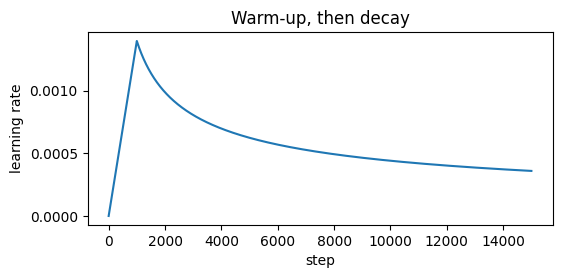

In [32]:
WARMUP, FACTOR = 1000, 0.5

def noam_lr(step, d_model=D_MODEL, warmup=WARMUP, factor=FACTOR):
    step = max(step, 1)
    return factor * d_model ** -0.5 * min(step ** -0.5, step * warmup ** -1.5)

steps = range(1, 15000)
plt.figure(figsize=(6, 2.5)); plt.plot(steps, [noam_lr(s) for s in steps])
plt.xlabel("step"); plt.ylabel("learning rate"); plt.title("Warm-up, then decay"); plt.show()

epoch  1 | step  1045 | train loss 4.141 | val loss 3.786 | 1.0 min
epoch  2 | step  2090 | train loss 3.165 | val loss 2.919 | 2.0 min
epoch  3 | step  3135 | train loss 2.867 | val loss 2.678 | 3.0 min
epoch  4 | step  3144 | train loss 2.865 | val loss 2.679 | 3.0 min


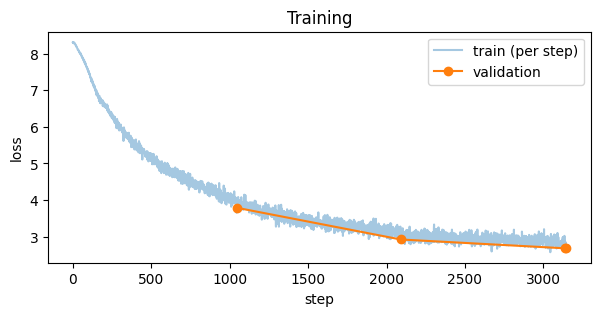

In [ ]:
TRAIN_MINUTES = 3      # lower this if you're short on time; even 3 minutes gives something
MAX_EPOCHS = 30
BATCH_SIZE = 128

torch.manual_seed(0)
model = Translator(V_EN, V_FR).to(device)
criterion = nn.CrossEntropyLoss(ignore_index=PAD, label_smoothing=0.1)
optimizer = torch.optim.Adam(model.parameters(), lr=1.0, betas=(0.9, 0.98), eps=1e-9)
scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lambda s: noam_lr(s + 1))
use_amp = device == "cuda"
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

@torch.no_grad()
def evaluate(model, data):
    model.eval()
    total, n = 0.0, 0
    for src, tgt in batches(data, 256, shuffle=False):
        with torch.autocast(device_type=device, dtype=torch.float16, enabled=use_amp):
            total += compute_loss(model, src, tgt, criterion).item() * len(src)
        n += len(src)
    return total / n

history, val_history = [], []
start = time.time()
for epoch in range(1, MAX_EPOCHS + 1):
    model.train()
    for src, tgt in batches(train_data, BATCH_SIZE):
        with torch.autocast(device_type=device, dtype=torch.float16, enabled=use_amp):
            loss = compute_loss(model, src, tgt, criterion)
        optimizer.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(optimizer); scaler.update(); scheduler.step()
        history.append(loss.item())
        if time.time() - start > TRAIN_MINUTES * 60:
            break
    val = evaluate(model, val_data)
    val_history.append((len(history), val))
    print(f"epoch {epoch:2d} | step {len(history):5d} | train loss {sum(history[-200:]) / len(history[-200:]):.3f} "
          f"| val loss {val:.3f} | {(time.time() - start) / 60:.1f} min")
    if time.time() - start > TRAIN_MINUTES * 60:
        break

torch.save(model.state_dict(), "translator.pt")
plt.figure(figsize=(7, 3))
plt.plot(history, alpha=0.4, label="train (per step)")
plt.plot(*zip(*val_history), "o-", label="validation")
plt.xlabel("step"); plt.ylabel("loss"); plt.legend(); plt.title("Training"); plt.show()

## I. Translate!

At inference time there's no correct French to feed in. We **generate**:

1. Encode the English **once**.
2. Start the French with `<s>`.
3. Run the decoder, take the logits at the **last** position, pick the most likely token (**greedy decoding**), append it.
4. Repeat until every sentence has produced `</s>` or we hit `max_len`.

### ✏️ Exercise I1: greedy decoding
Do the whole batch at once; the only loop is over output positions. Keep a `done` flag per sentence; once a sentence is done, append `PAD` instead of new tokens.

In [ ]:
@torch.no_grad()
def greedy_decode(model, src, max_len=MAX_LEN):
    '''src: [B, S] → [B, ≤ max_len] French token IDs, starting with BOS'''
    model.eval()
    # ✏️ YOUR CODE HERE (about 9 lines)
    raise NotImplementedError

In [ ]:
src, tgt = next(batches(test_data, 8, shuffle=False))
out = greedy_decode(model, src)
check("starts with BOS", (out[:, 0] == BOS).all().item())
check("respects max_len", out.size(1) <= MAX_LEN)
after_eos = (out == EOS).int().cumsum(1) - (out == EOS).int()        # positions strictly after the first EOS
check("only PAD after EOS", (out[after_eos > 0] == PAD).all().item())

def translate(sentences):
    src = pad_batch([encode(en_tok, s) for s in sentences]).to(device)
    return [decode(fr_tok, ids) for ids in greedy_decode(model, src)]

for en, fr in [(d[2], d[3]) for d in test_data[:10]]:
    print(f"EN:    {en}\nREF:   {fr}\nMODEL: {translate([en])[0]}\n")

Passed: starts with BOS
Passed: respects max_len
Passed: only PAD after EOS
EN:    I knew this day would come.
REF:   Je savais que ce jour viendrait.
MODEL: je savais que ce jour viendrait.

EN:    My wife isn't beautiful. Yours is.
REF:   Ma femme n'est pas belle. La tienne oui.
MODEL: ma femme n'est pas belle.

EN:    She wants to extend the no-smoking area.
REF:   Elle veut étendre la zone non-fumeurs.
MODEL: elle veut prendre le nez de plus.

EN:    I know I'm not the brightest girl in the world.
REF:   Je sais que je ne suis pas une lumière.
MODEL: je ne sais pas que je sois la plus belle fille au monde.

EN:    Let me write down the address.
REF:   Je vais noter l'adresse.
MODEL: laisse-moi écrire l'adresse à l'armence.

EN:    I'm at Tokyo Station now.
REF:   Je suis à la gare de Tokyo en ce moment.
MODEL: je suis à tokyo maintenant.

EN:    You were told to stay on the ship.
REF:   On t'avait dit de rester sur le bateau.
MODEL: vous avez dit de rester sur le bateau.

EN:    Sh

In [ ]:
# @title Solution: run this cell if you're stuck, then re-run the check above
@torch.no_grad()
def greedy_decode(model, src, max_len=MAX_LEN):
    '''src: [B, S] → [B, ≤ max_len] French token IDs, starting with BOS'''
    model.eval()
    memory, src_mask = model.encode(src)                              # encoder runs once
    ys = torch.full((src.size(0), 1), BOS, dtype=torch.long, device=src.device)
    done = torch.zeros(src.size(0), dtype=torch.bool, device=src.device)
    for _ in range(max_len - 1):
        next_tok = model.decode(ys, memory, src_mask)[:, -1].argmax(-1)   # [B]
        next_tok = next_tok.masked_fill(done, PAD)                     # finished sentences just pad
        ys = torch.cat([ys, next_tok.unsqueeze(1)], dim=1)
        done |= next_tok == EOS
        if done.all():
            break
    return ys

### How good is it? BLEU

**BLEU** counts how many 1- to 4-word chunks of the model's output also appear in the reference translation (0–100, higher is better). It's crude: a correct paraphrase scores low. For reference, the original paper's big model reached 41 BLEU on a much harder news benchmark.

In [ ]:
import sacrebleu

hyps, refs = [], []
for i in range(0, len(test_data), 128):
    chunk = test_data[i:i + 128]
    src = pad_batch([d[0] for d in chunk]).to(device)
    hyps += [decode(fr_tok, ids) for ids in greedy_decode(model, src)]
    refs += [norm(fr_tok, d[3]) for d in chunk]
print(f"Test BLEU: {sacrebleu.corpus_bleu(hyps, [refs]).score:.1f}")

Test BLEU: 29.4


### Where does French look in the English? Cross-attention

Each row is a French token being generated; each column is an English token. Bright cells show what the decoder looked at. After training you should see a rough diagonal that bends where word order differs (adjectives after nouns, for example).

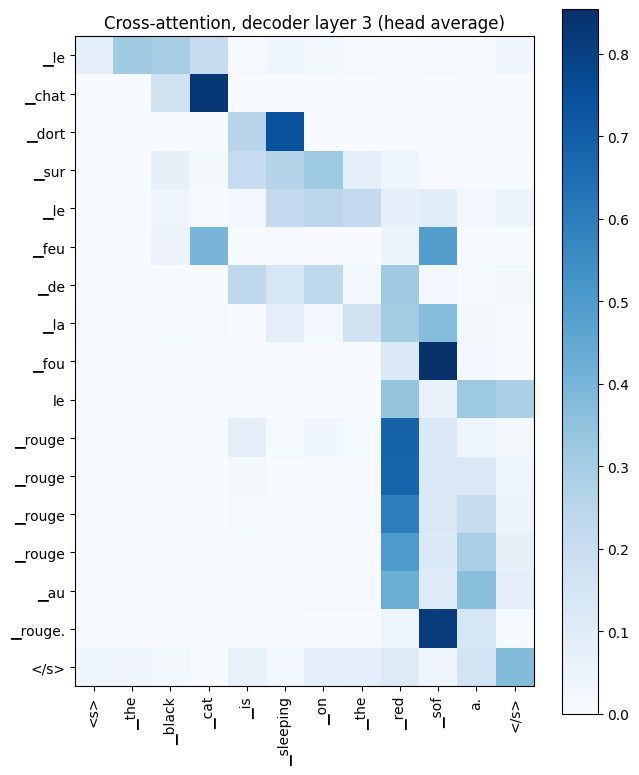

→ le chat dort sur le feu de la foule rouge rouge rouge rouge au rouge.


In [ ]:
def show_cross_attention(sentence, layer=-1):
    src = torch.tensor([encode(en_tok, sentence)], device=device)
    out = greedy_decode(model, src)
    ids = out[0][: (out[0] == EOS).nonzero()[0].item() + 1] if (out[0] == EOS).any() else out[0]
    with torch.no_grad():
        memory, src_mask = model.encode(src)
        model.decode(ids[:-1].unsqueeze(0), memory, src_mask)        # re-run to record the weights
    w = model.decoder.layers[layer].cross_attn.last_weights[0].mean(0).float().cpu()   # average over heads
    x_labels = [en_tok.id_to_token(int(t)) for t in src[0]]
    y_labels = [fr_tok.id_to_token(int(t)) for t in ids[1:]]        # the token produced at each step
    show_attention(w, x_labels, y_labels, f"Cross-attention, decoder layer {layer % N_LAYERS + 1} (head average)")
    print("→", decode(fr_tok, ids))

show_cross_attention("The black cat is sleeping on the red sofa.")

## J. Play with it

Type your own sentence. Keep it short and simple: the model only saw Tatoeba-style sentences, mostly under 15 words.

j'aimerais une tasse de café, je te prie.


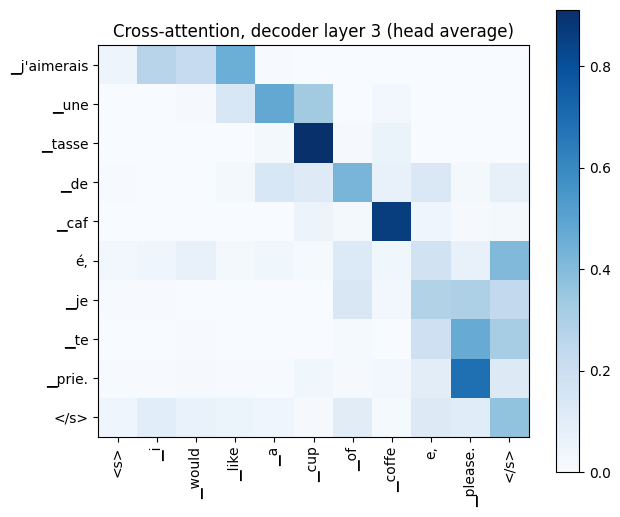

→ j'aimerais une tasse de café, je te prie.


In [ ]:
sentence = "I would like a cup of coffee, please."  # @param {type:"string"}
print(translate([sentence])[0])
show_cross_attention(sentence)

### Challenges (for the fast and the curious)

1. **Temperature sampling.** Instead of `argmax`, sample from `softmax(logits / T)`. What happens at `T = 0.5`? At `T = 1.5`? (This is what the temperature slider in ChatGPT does.)
2. **Beam search.** Keep the `k` best partial translations at every step instead of just one. Does BLEU go up?
3. **Ablations.** Remove positional encoding (`self.pos` just returns `x`) and retrain. What happens to word order? Try post-LN instead of pre-LN.
4. **Scale it.** `D_MODEL = 256`, 8 heads, more minutes. How much better does it get?
5. **Flip it.** Train French → English by swapping the tokenizers and the pair order.

### Coming up in Workshop 3

Look at `greedy_decode`: at every step it re-runs the decoder over **all** previous tokens. That's wasteful, since the keys and values for old tokens never change. Next time: the **KV cache**, sampling strategies, how **precision and quantization** (fp16, int8, 4-bit) make big models fit and run fast, and a first look at **RL** for language models.

---
**Further reading:** [Attention Is All You Need](https://arxiv.org/abs/1706.03762) · [The Annotated Transformer](https://nlp.seas.harvard.edu/annotated-transformer/) · [ARENA: Transformers from scratch](https://arena-chapter1-transformer-interp.streamlit.app/) · [3Blue1Brown: Attention in transformers](https://www.youtube.com/watch?v=eMlx5fFNoYc)

*Made for UTMIST. Data: Tatoeba (CC-BY 2.0 FR) via the PyTorch tutorials mirror.*